# Principal Component Analysis (PCA)

**Input:** `cluster_sample_unlabeled.csv` (features), `cluster_sample_labels.csv` (used only to color plots)  
**Method:** PCA on log-transformed, standardized features  
**Outputs:** explained variance, component scores, variable loadings

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

sns.set_style("whitegrid")
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)

SEED = 42

## 1. Load Data

In [2]:
X = pd.read_csv("cluster_sample_unlabeled.csv")
labels = pd.read_csv("cluster_sample_labels.csv")["Label"]

print(f"Features: {X.shape[0]:,} rows x {X.shape[1]} columns")

Features: 11,720 rows x 65 columns


## 2. Transform and Scale

The same preprocessing as the clustering notebook is applied: a sign-preserving log transform to reduce skew, then standardization to mean 0 and standard deviation 1. PCA is variance-based, so features must be on a comparable scale.

In [3]:
X_log = np.sign(X) * np.log1p(X.abs())
Z = StandardScaler().fit_transform(X_log)

print(f"Mean of every feature is 0: {np.allclose(Z.mean(axis=0), 0)}")
print(f"Std of every feature is 1:  {np.allclose(Z.std(axis=0), 1)}")

Mean of every feature is 0: True
Std of every feature is 1:  True


## 3. Fit PCA

PCA is fit with all components. Each eigenvalue is the variance captured by one principal component. Because the features are standardized, the total variance equals the number of features.

In [4]:
pca = PCA(random_state=SEED).fit(Z)

eigenvalues = pca.explained_variance_
ratio = pca.explained_variance_ratio_
cumulative = np.cumsum(ratio)
scores = pca.transform(Z)

summary = pd.DataFrame({
    "eigenvalue": eigenvalues[:10],
    "variance explained": ratio[:10],
    "cumulative": cumulative[:10],
}, index=[f"PC{i}" for i in range(1, 11)])

print(f"Total variance (equals number of features): {eigenvalues.sum():.1f}")
for target in (0.80, 0.90, 0.95):
    n = int(np.searchsorted(cumulative, target)) + 1
    print(f"Components needed for {target:.0%} of variance: {n} of {Z.shape[1]}")
print(f"Components with eigenvalue > 1: {(eigenvalues > 1).sum()}")

summary.round(3)

Total variance (equals number of features): 65.0
Components needed for 80% of variance: 6 of 65
Components needed for 90% of variance: 10 of 65
Components needed for 95% of variance: 13 of 65
Components with eigenvalue > 1: 10


,eigenvalue,variance explained,cumulative
PC1,25.501,0.392,0.392
PC2,12.837,0.197,0.590
PC3,5.943,0.091,0.681
PC4,3.417,0.053,0.734
PC5,3.307,0.051,0.785
PC6,2.270,0.035,0.820
PC7,1.883,0.029,0.849
PC8,1.652,0.025,0.874
PC9,1.377,0.021,0.895
PC10,1.152,0.018,0.913


## 4. Scree Plot and Cumulative Variance

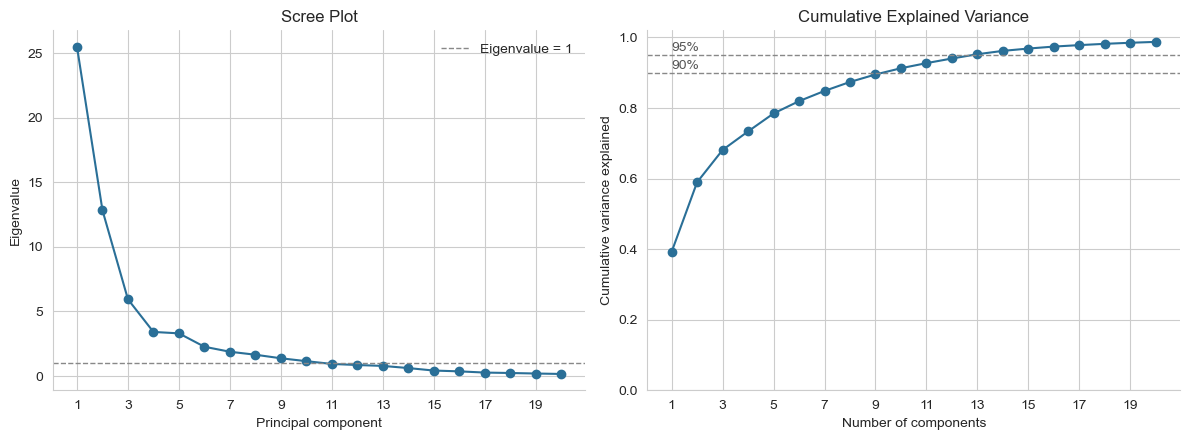

In [5]:
n_show = 20
pcs = np.arange(1, n_show + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(pcs, eigenvalues[:n_show], marker="o", color="#2a6f97")
axes[0].axhline(1, color="#888888", linestyle="--", linewidth=1, label="Eigenvalue = 1")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Eigenvalue")
axes[0].set_title("Scree Plot")
axes[0].set_xticks(pcs[::2])
axes[0].legend(frameon=False)

axes[1].plot(pcs, cumulative[:n_show], marker="o", color="#2a6f97")
for target in (0.90, 0.95):
    axes[1].axhline(target, color="#888888", linestyle="--", linewidth=1)
    axes[1].text(1, target + 0.012, f"{target:.0%}", ha="left", color="#555555")
axes[1].set_xlabel("Number of components")
axes[1].set_ylabel("Cumulative variance explained")
axes[1].set_title("Cumulative Explained Variance")
axes[1].set_xticks(pcs[::2])
axes[1].set_ylim(0, 1.02)

plt.tight_layout()
plt.savefig("figures/pca-01-scree-cumulative.png", dpi=150)
plt.show()

## 5. Samples in Principal Component Space

Each point is one network flow. Known traffic types are used only to color the points; PCA does not use them.

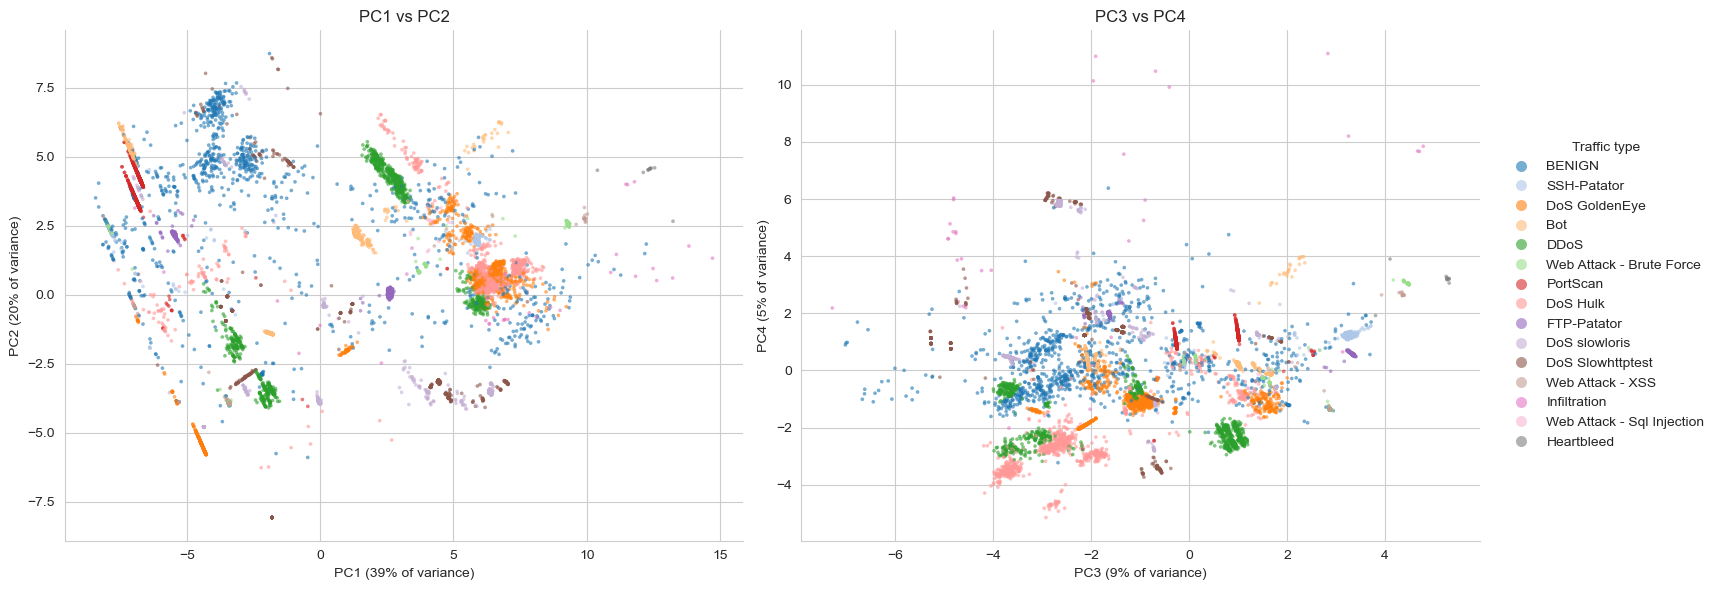

In [6]:
order = labels.value_counts().index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    sns.scatterplot(x=scores[:, a], y=scores[:, b], hue=labels, hue_order=order,
                    palette="tab20", s=7, alpha=0.6, linewidth=0, ax=ax)
    ax.set_xlabel(f"PC{a + 1} ({ratio[a]:.0%} of variance)")
    ax.set_ylabel(f"PC{b + 1} ({ratio[b]:.0%} of variance)")
    ax.set_title(f"PC{a + 1} vs PC{b + 1}")
    ax.get_legend().remove()

handles, names = axes[0].get_legend_handles_labels()
fig.legend(handles, names, loc="center left", bbox_to_anchor=(1.0, 0.5),
           frameon=False, markerscale=3, title="Traffic type")

plt.tight_layout()
plt.savefig("figures/pca-02-pc-scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Relationship Between Variables and Components

A loading is the weight of one original feature in one principal component. Large positive or negative loadings show which features define that component. The heatmap shows the six largest-loading features of each of the first four components, grouped by the component they load on most.

In [7]:
loadings = pd.DataFrame(
    pca.components_[:4].T,
    index=X.columns,
    columns=["PC1", "PC2", "PC3", "PC4"],
)

for pc in ["PC1", "PC2", "PC3"]:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(6)
    print(f"{pc} - largest loadings")
    print(top.round(3).to_string())
    print()

PC1 - largest loadings
Bwd IAT Std               0.177
Bwd IAT Total             0.176
Bwd IAT Max               0.175
Fwd Packet Length Std     0.173
Bwd IAT Mean              0.171
Packet Length Variance    0.167

PC2 - largest loadings
Flow Bytes/s     0.247
Fwd IAT Mean    -0.208
Flow IAT Mean   -0.205
Fwd IAT Max     -0.198
Fwd IAT Total   -0.194
Fwd IAT Min     -0.192

PC3 - largest loadings
PSH Flag Count            0.279
Idle Max                 -0.275
Idle Mean                -0.275
Idle Min                 -0.274
Init_Win_bytes_forward    0.270
Active Mean              -0.229



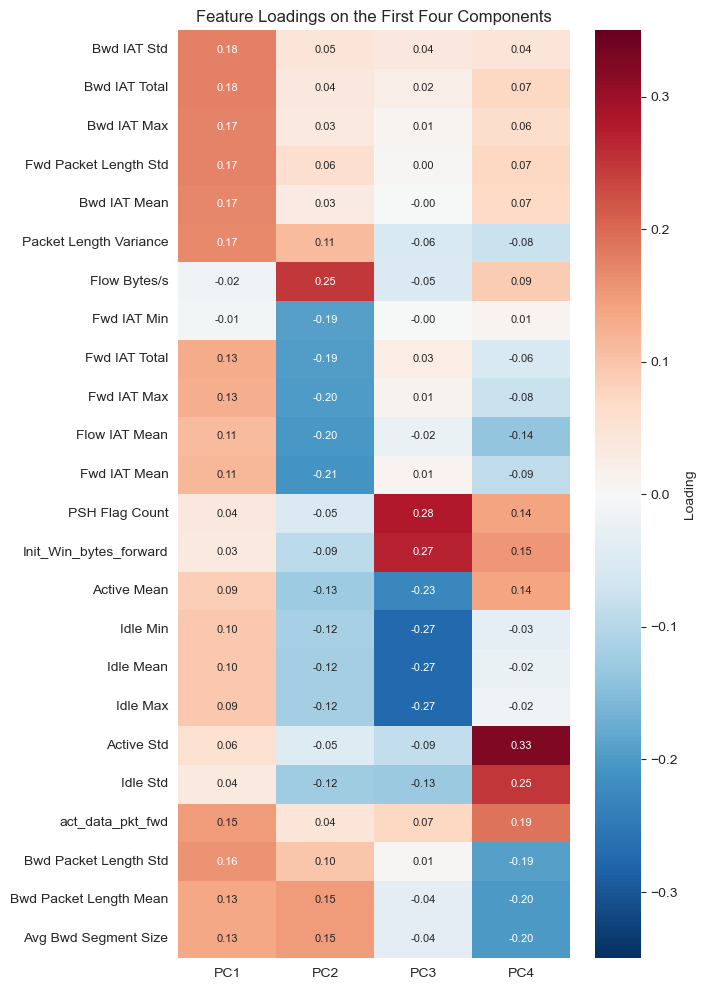

In [8]:
selected = []
for pc in loadings.columns:
    selected += loadings[pc].abs().sort_values(ascending=False).head(6).index.tolist()
selected = list(dict.fromkeys(selected))

home_pc = loadings.loc[selected].abs().idxmax(axis=1)
heat = loadings.loc[selected].copy()
heat["home"] = home_pc
heat["strength"] = [loadings.loc[f, home_pc[f]] for f in heat.index]
heat = heat.sort_values(["home", "strength"], ascending=[True, False])[["PC1", "PC2", "PC3", "PC4"]]

plt.figure(figsize=(7, 10))
sns.heatmap(heat, cmap="RdBu_r", center=0, vmin=-0.35, vmax=0.35,
            annot=True, fmt=".2f", annot_kws={"size": 8},
            cbar_kws={"label": "Loading"})
plt.title("Feature Loadings on the First Four Components")
plt.ylabel("")
plt.tight_layout()
plt.savefig("figures/pca-03-loadings-heatmap.png", dpi=150)
plt.show()

## 7. Biplot

Points are flows projected onto PC1 and PC2. Arrows show eight of the features with the largest loadings on these two components, skipping features that point in almost the same direction as one already shown. Arrows that point the same way describe features that increase together.

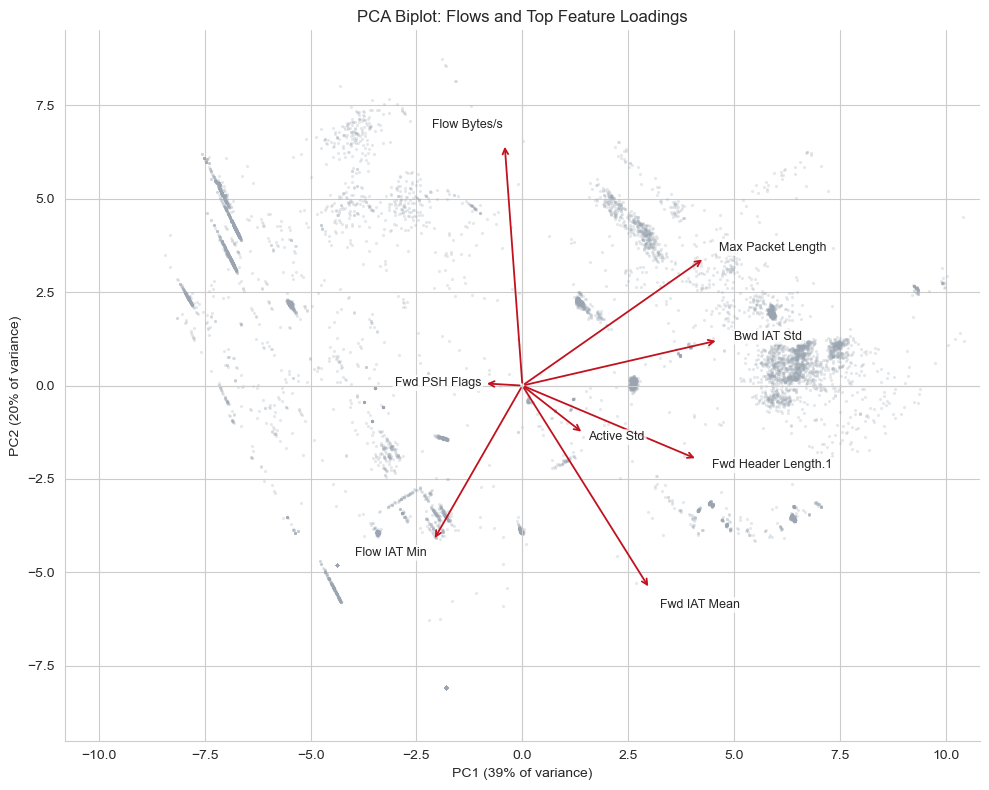

In [9]:
l12 = loadings[["PC1", "PC2"]]
norms = np.sqrt((l12 ** 2).sum(axis=1)).sort_values(ascending=False)

chosen = []
for name in norms.index:
    v = l12.loc[name].values / norms[name]
    if all(abs(v @ (l12.loc[c].values / norms[c])) < 0.97 for c in chosen):
        chosen.append(name)
    if len(chosen) == 8:
        break

lim = np.percentile(np.abs(scores[:, :2]), 99.5)
arrow_scale = 0.75 * lim / norms[chosen[0]]

fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(scores[:, 0], scores[:, 1], s=5, alpha=0.25, color="#9aa5b1", linewidth=0)

for name in chosen:
    x, y = l12.loc[name, "PC1"] * arrow_scale, l12.loc[name, "PC2"] * arrow_scale
    ax.annotate("", xy=(x, y), xytext=(0, 0),
                arrowprops=dict(arrowstyle="->", color="#c1121f", linewidth=1.3))
    ax.text(x * 1.08, y * 1.08, name, fontsize=9, ha="left" if x >= 0 else "right", va="center",
            bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="none", alpha=0.8))

ax.set_xlim(-lim * 1.25, lim * 1.25)
ax.set_ylim(-lim * 1.1, lim * 1.1)
ax.axhline(0, color="#cccccc", linewidth=0.8)
ax.axvline(0, color="#cccccc", linewidth=0.8)
ax.set_xlabel(f"PC1 ({ratio[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({ratio[1]:.0%} of variance)")
ax.set_title("PCA Biplot: Flows and Top Feature Loadings")

plt.tight_layout()
plt.savefig("figures/pca-04-biplot.png", dpi=150)
plt.show()

## 8. Summary of Results

In [10]:
n90 = int(np.searchsorted(cumulative, 0.90)) + 1

print(f"Features: {Z.shape[1]}")
print(f"PC1 explains {ratio[0]:.1%}, PC2 explains {ratio[1]:.1%}, PC1 + PC2 explain {cumulative[1]:.1%}")
print(f"Components for 90% of variance: {n90} ({n90 / Z.shape[1]:.0%} of the original features)")
print(f"Components with eigenvalue > 1: {(eigenvalues > 1).sum()}")
print()
print("Figures saved to figures/: pca-01 to pca-04")

Features: 65
PC1 explains 39.2%, PC2 explains 19.7%, PC1 + PC2 explain 59.0%
Components for 90% of variance: 10 (15% of the original features)
Components with eigenvalue > 1: 10

Figures saved to figures/: pca-01 to pca-04
